# Hospital Dependency Resilience Platform - Experiment Notebook

**Synthetic data and simulated partner services. Not for production clinical use.**

This notebook re-runs the *real* experiment suite (the same code the application uses, on a virtual clock) and analyses the results. Nothing here is hard-coded: every number is read from the result files produced by the run.

**Question:** does core-service availability improve sufficiently during simulated partner failures when a resilience layer (timeout, bounded retry, circuit breaker, truthful fallback) replaces a simple baseline?

**Primary metric:** core availability = successful core requests / total core requests x 100 (core request = one patient visit).

In [1]:
import os, sys, json
os.chdir(os.path.abspath('..')) if os.path.basename(os.getcwd()) == 'experiments' else None
sys.path.insert(0, os.getcwd())
import pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from experiments.runner import run_suite
from src.utils.config_manager import ConfigManager
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)

## 1. Run the experiment suite (identical workload, faults and partner randomness for both modes)

In [2]:
cm = ConfigManager('config/config.yaml', persist=False)
summary = run_suite(cm, results_dir='data/results', figures_dir='outputs/figures', reports_dir='docs', verbose=True)

  S1 Normal operation                   baseline  99.00%   resilient 100.00%
  S2 Laboratory high latency            baseline  99.33%   resilient 100.00%
  S3 Pharmacy intermittent failure      baseline  77.33%   resilient 100.00%
  S4 Insurance complete outage          baseline   8.33%   resilient 100.00%


  S5 Telemedicine timeout               baseline   8.00%   resilient 100.00%
  S6 Partner recovery                   baseline  66.00%   resilient 100.00%
  S7 Insurance transient failures       baseline  66.67%   resilient 100.00%
  S8 Laboratory consecutive failures    baseline  50.00%   resilient 100.00%



  Baseline  : 59.33%
  Target    : 95.00%
  Resilient : 100.00%
  Improvement: 40.67 pp
  Target ACHIEVED


## 2. Target / result

In [3]:
s = json.load(open('data/results/experiment_summary.json'))
print(f"Baseline  : {s['baseline_core_availability_pct']:.2f}%")
print(f"Target    : {s['target_core_availability_pct']:.2f}%")
print(f"Resilient : {s['resilient_core_availability_pct']:.2f}%")
print(f"Improvement: {s['improvement_pp']:.2f} percentage points")
print('Target    :', 'Achieved' if s['target_achieved'] else 'Not achieved')
print(f"Within {s['latency_slo_s']}s SLO: baseline {s['baseline_within_slo_pct']:.2f}% / resilient {s['resilient_within_slo_pct']:.2f}%")

Baseline  : 59.33%
Target    : 95.00%
Resilient : 100.00%
Improvement: 40.67 percentage points
Target    : Achieved
Within 5.0s SLO: baseline 45.92% / resilient 98.00%


## 3. Per-scenario comparison

In [4]:
comp = pd.read_csv('data/results/comparison_results.csv')
cols = ['scenario_id','scenario','baseline_core_availability_pct','resilient_core_availability_pct','availability_improvement_pp',
        'baseline_within_slo_pct','resilient_within_slo_pct','baseline_cascading_failures','resilient_cascading_failures']
comp[cols]

,scenario_id,scenario,baseline_core_availability_pct,resilient_core_availability_pct,availability_improvement_pp,baseline_within_slo_pct,resilient_within_slo_pct,baseline_cascading_failures,resilient_cascading_failures
0,S1,Normal operation,99.00,100.0,1.00,99.00,100.00,3,0
1,S2,Laboratory high latency,99.33,100.0,0.67,8.00,98.33,2,0
2,S3,Pharmacy intermittent failure,77.33,100.0,22.67,69.00,95.67,68,0
3,S4,Insurance complete outage,8.33,100.0,91.67,8.33,100.00,275,0
4,S5,Telemedicine timeout,8.00,100.0,92.00,8.00,98.33,276,0
5,S6,Partner recovery,66.00,100.0,34.00,66.00,100.00,102,0
6,S7,Insurance transient failures,66.67,100.0,33.33,59.00,91.67,100,0
7,S8,Laboratory consecutive failures,50.00,100.0,50.00,50.00,100.00,150,0


In [5]:
comp[['scenario_id','baseline_avg_latency_ms','resilient_avg_latency_ms','baseline_p95_latency_ms','resilient_p95_latency_ms',
      'baseline_retry_count','resilient_retry_count','resilient_timeout_count','resilient_fallback_count',
      'resilient_circuit_open_count','resilient_fail_fast_count','baseline_recovery_time_s','resilient_recovery_time_s']]

,scenario_id,baseline_avg_latency_ms,resilient_avg_latency_ms,baseline_p95_latency_ms,resilient_p95_latency_ms,baseline_retry_count,resilient_retry_count,resilient_timeout_count,resilient_fallback_count,resilient_circuit_open_count,resilient_fail_fast_count,baseline_recovery_time_s,resilient_recovery_time_s
0,S1,405.8,417.2,524.0,523.9,56,59,0,0,0,0,NaN,NaN
1,S2,1549.9,511.0,5157.3,2000.0,59,54,100,275,90,185,NaN,NaN
2,S3,1045.2,531.3,10387.1,1796.4,160,175,55,111,37,74,NaN,NaN
3,S4,290.5,299.3,483.7,494.7,301,52,0,275,95,180,NaN,NaN
4,S5,4911.3,497.3,20000.0,2000.0,317,53,100,275,90,185,NaN,NaN
5,S6,365.3,383.6,523.7,524.3,144,64,0,103,35,68,0.88,3.82
6,S7,1265.2,532.6,10490.9,1225.0,197,143,51,161,52,109,NaN,NaN
7,S8,442.8,395.3,613.1,524.7,177,66,0,150,50,100,0.32,0.32


## 4. Charts

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
x = range(len(comp)); w = 0.38
for ax, (b, r, t) in zip(axes.ravel(), [('baseline_core_availability_pct','resilient_core_availability_pct','Core availability (%)'),
    ('baseline_avg_latency_ms','resilient_avg_latency_ms','Average request latency (ms)'),
    ('baseline_p95_latency_ms','resilient_p95_latency_ms','P95 request latency (ms)'),
    ('baseline_request_failure_rate_pct','resilient_request_failure_rate_pct','Partner-operation failure rate (%)')]):
    ax.bar([i - w/2 for i in x], comp[b], w, label='baseline', color='#e74c3c'); ax.bar([i + w/2 for i in x], comp[r], w, label='resilient', color='#2ecc71')
    ax.set_xticks(list(x)); ax.set_xticklabels(comp.scenario_id); ax.set_title(t); ax.legend(); ax.grid(axis='y', alpha=.3)
axes[0,0].axhline(s['target_core_availability_pct'], color='#f39c12', ls='--')
plt.tight_layout(); plt.show()

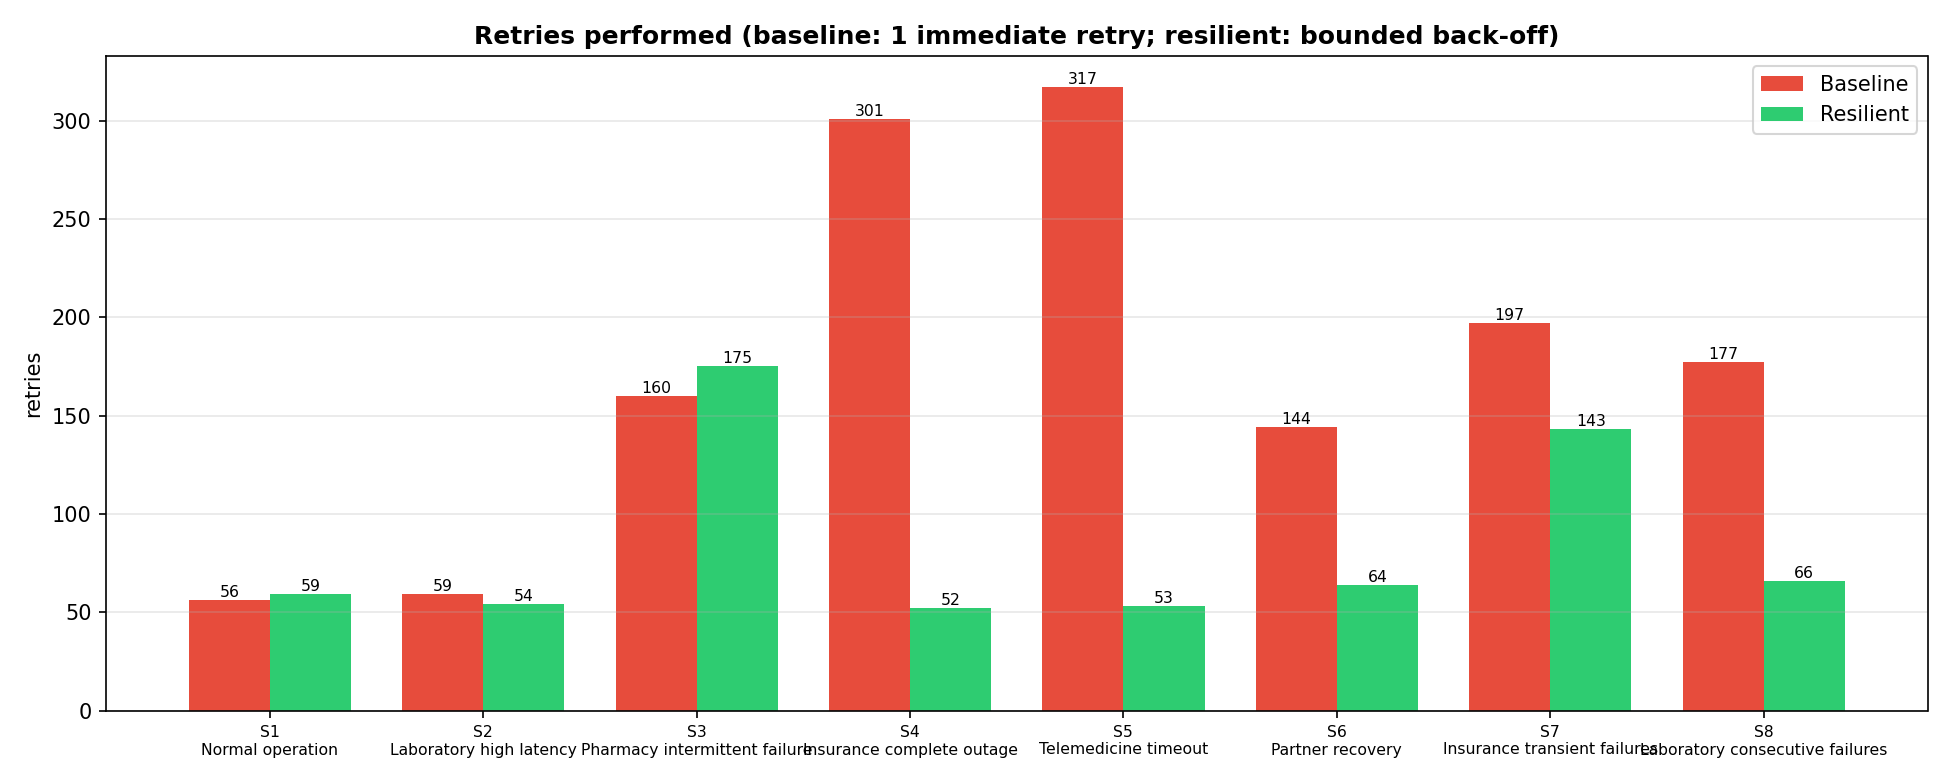

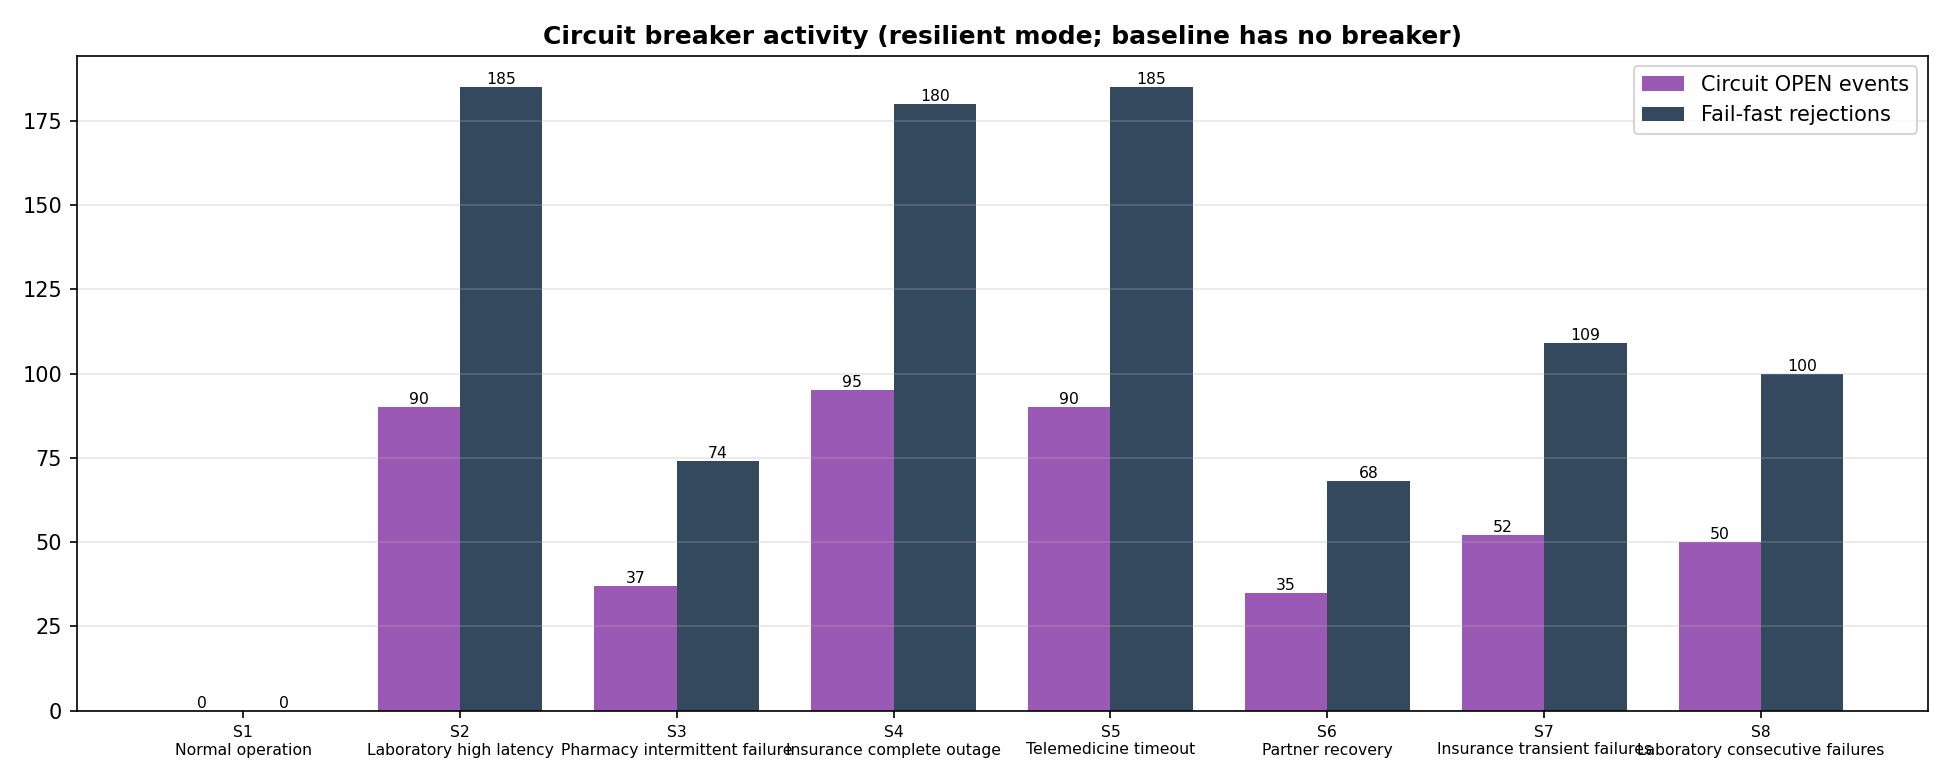

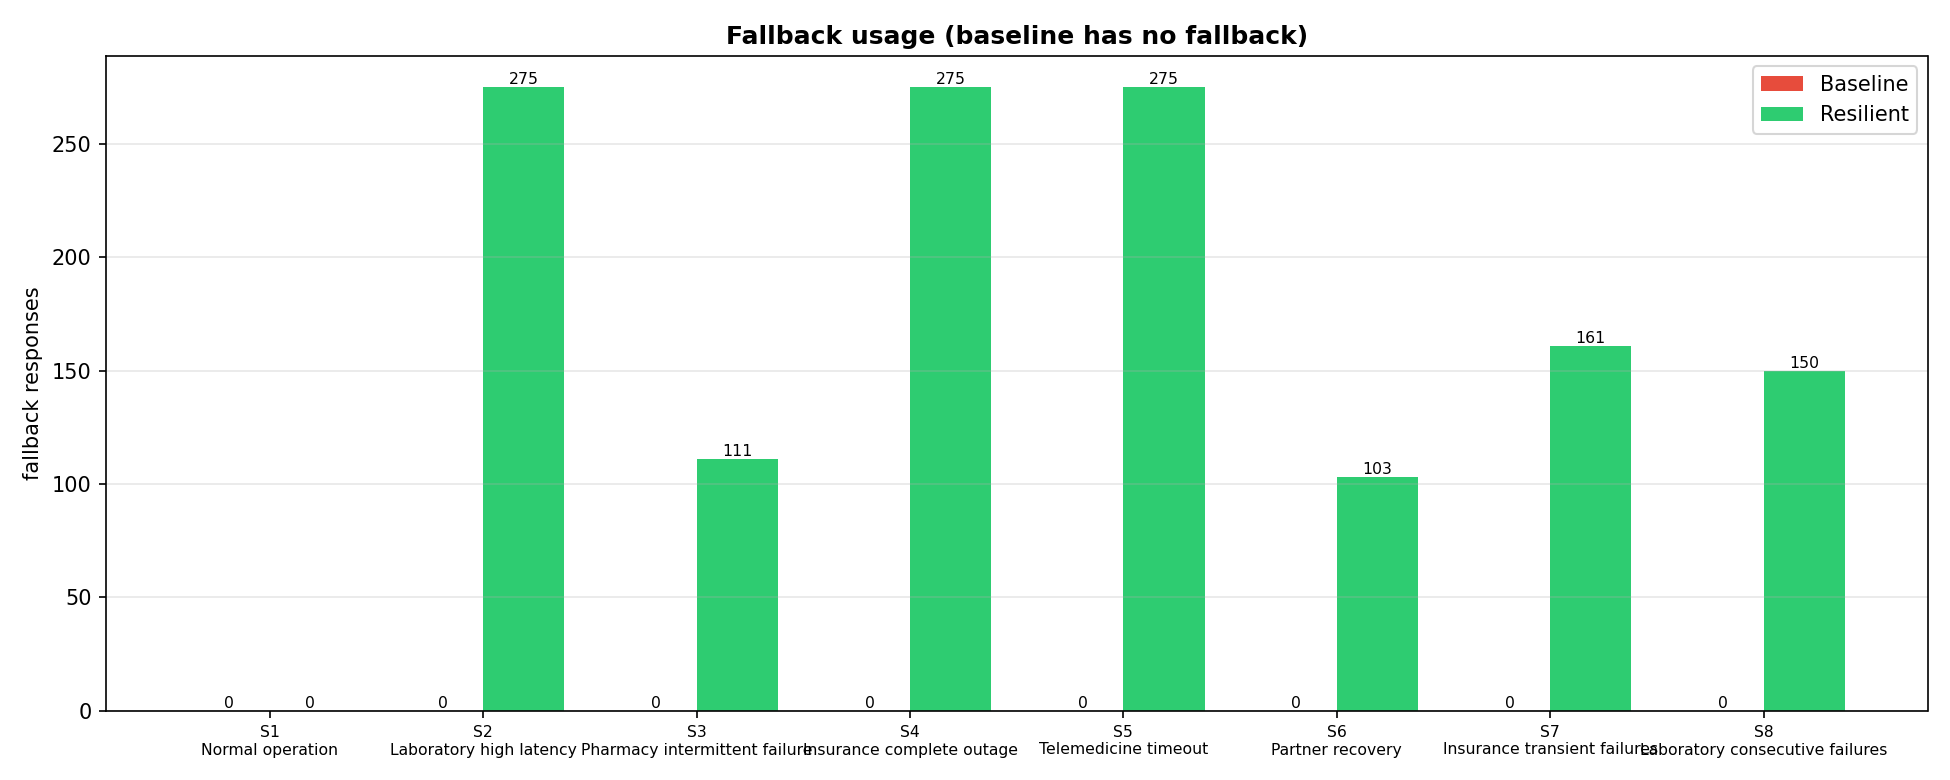

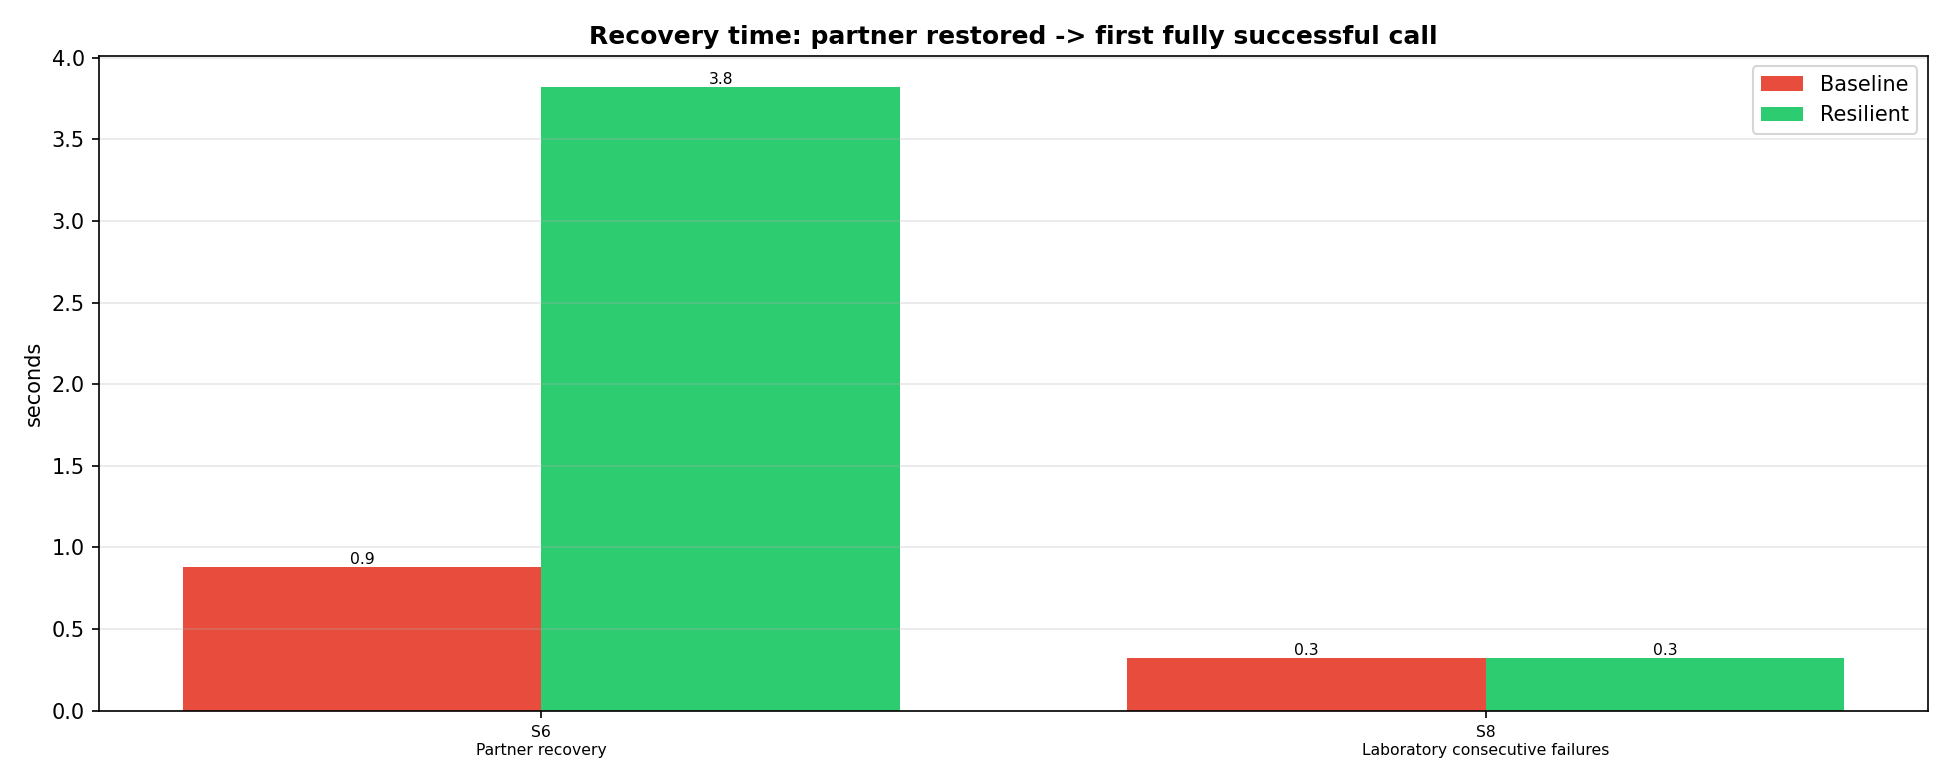

In [7]:
for f in ['retry_count_comparison','circuit_breaker_events','fallback_usage','recovery_time_comparison']:
    display(Image(f'outputs/figures/{f}.png'))

## 5. Retry / circuit-breaker trace (scripted partner outcomes, real resilience code)

Insurance: timeout, timeout, success -> `retry_count = 2`. Laboratory: consecutive failures -> retries -> circuit OPEN -> truthful fallback -> fail-fast -> recovery -> HALF_OPEN -> CLOSED.

In [8]:
pd.read_csv('data/results/retry_trace_demo.csv')[['step','attempts','retry_count','status','fallback_used','circuit_state','latency_ms']]

,step,attempts,retry_count,status,fallback_used,circuit_state,latency_ms
0,"Insurance transient failure (timeout, timeout,...",1:TIMEOUT -> 2:TIMEOUT -> 3:SUCCESS,2,RECOVERED,False,CLOSED,7092.1
1,"Laboratory failure: retries exhaust, circuit o...",1:HTTP_502 -> 2:HTTP_502 -> 3:HTTP_502,2,DEGRADED,True,OPEN,1518.6
2,"Laboratory: circuit OPEN -> fail fast, no part...",none (circuit open),0,CIRCUIT_OPEN,True,OPEN,0.0
3,"Partner recovered, but circuit still OPEN (tim...",none (circuit open),0,CIRCUIT_OPEN,True,OPEN,0.0
4,Recovery timeout passed -> HALF_OPEN trial suc...,1:SUCCESS,0,RECOVERED,False,CLOSED,287.7
5,Normal operation resumed,1:SUCCESS,0,SUCCESS,False,CLOSED,307.3


## 6. Error analysis from the raw call log (seed 11)

In [9]:
calls = pd.read_csv([f'data/results/{f}' for f in os.listdir('data/results') if f.startswith('experiment_calls_seed')][0])
calls.groupby(['scenario_id','mode','status']).size().unstack(fill_value=0)

status                 CIRCUIT_OPEN  DEGRADED  ERROR  RECOVERED  SUCCESS  TEMPORARILY_UNAVAILABLE  TIMEOUT
scenario_id mode                                                                                          
S1          baseline              0         0      1          0      236                        0        0
            resilient             0         0      0         14      226                        0        0
S2          baseline              0         0      0          0      240                        0        0
            resilient            37         0      0          9      176                        0       18
S3          baseline              0         0     20          0      183                        0        0
            resilient            15         3      0         27      191                        2        2
S4          baseline              0         0     55          0      129                        0        0
            resilient            36         0      0          7      178                       19        0
S5          baseline              0         0     55          0      185                        0        0
            resilient            37         0      0         11      174                        0       18
S6          baseline              0         0     20          0      180                        0        0
            resilient            14         0      0         12      207                        7        0
S7          baseline              0         0     20          0      200                        0        0
            resilient            22         2      0         15      192                        7        2
S8          baseline              0         0     30          0      120                        0        0
            resilient            20        10      0         12      198                        0        0

In [10]:
print('Where is the resilient system worse than the baseline?')
worse = comp[(comp.resilient_avg_latency_ms > comp.baseline_avg_latency_ms) | (comp.resilient_request_success_rate_pct < comp.baseline_request_success_rate_pct)]
worse[['scenario_id','scenario','baseline_avg_latency_ms','resilient_avg_latency_ms','baseline_request_success_rate_pct','resilient_request_success_rate_pct']]

Where is the resilient system worse than the baseline?


,scenario_id,scenario,baseline_avg_latency_ms,resilient_avg_latency_ms,baseline_request_success_rate_pct,resilient_request_success_rate_pct
0,S1,Normal operation,405.8,417.2,99.75,100.00
1,S2,Laboratory high latency,1549.9,511.0,99.83,77.08
2,S3,Pharmacy intermittent failure,1045.2,531.3,93.63,90.75
3,S4,Insurance complete outage,290.5,299.3,70.24,77.08
5,S6,Partner recovery,365.3,383.6,89.74,91.42
6,S7,Insurance transient failures,1265.2,532.6,90.87,86.58


## 7. Interpretation (read with the caveats)

- Core availability counts a visit as successful when it completes without a partner error reaching the core; a visit that used a truthful fallback is *completed but degraded*. Compare with `request_success_rate_pct`, which only counts partner operations that really completed.
- Retries and back-off cost latency before the breaker opens; the breaker also delays the return to full service after a partner recovers.
- Partners are simulators and visits are processed sequentially; results demonstrate the mechanisms, not production performance.